In [1]:
import constants_units as cu
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import dispatch
import matplotlib
matplotlib.rcParams["figure.figsize"] = [10., 8.]
matplotlib.rcParams["figure.dpi"] = 300.
matplotlib.rcParams["font.size"] = 28.

In [2]:
colors = ["C0", "C1", "C2", "C4"]

In [3]:
def drawPatch(patch, i):
    llc = patch.llc_nat[0:3:2]
    llc = [coord for coord in llc]
    width, height = [size for size in patch.size[0:3:2]]
    axes.add_patch(patches.Rectangle(llc, width, height,
        color = colors[i%3], fill = False))    

In [4]:
def drawScaleHeight(radMin, radMax):
    stellarMass = 1.989e33
    temp = 280.
    tempExp = -0.5
    meanMolWeight = 2.33
    
    rads = np.linspace(radMin, radMax, num = 100)    
    KeplerVels = [np.sqrt(cu.gravConst*stellarMass/rad/cu.au) \
        for rad in rads]
    temps = [temp*rad**tempExp for rad in rads]
    soundSpeeds = [np.sqrt(cu.idealGasConst*temp/meanMolWeight) \
        for temp in temps]
    scaleHeights = [rads[i]*soundSpeeds[i]/KeplerVels[i] \
        for i in range(100)]
    axes.plot(rads, scaleHeights, "k-", linewidth = 1)
    scaleHeights = [-scaleHeight for scaleHeight in scaleHeights]
    axes.plot(rads, scaleHeights, "k-", linewidth = 1)

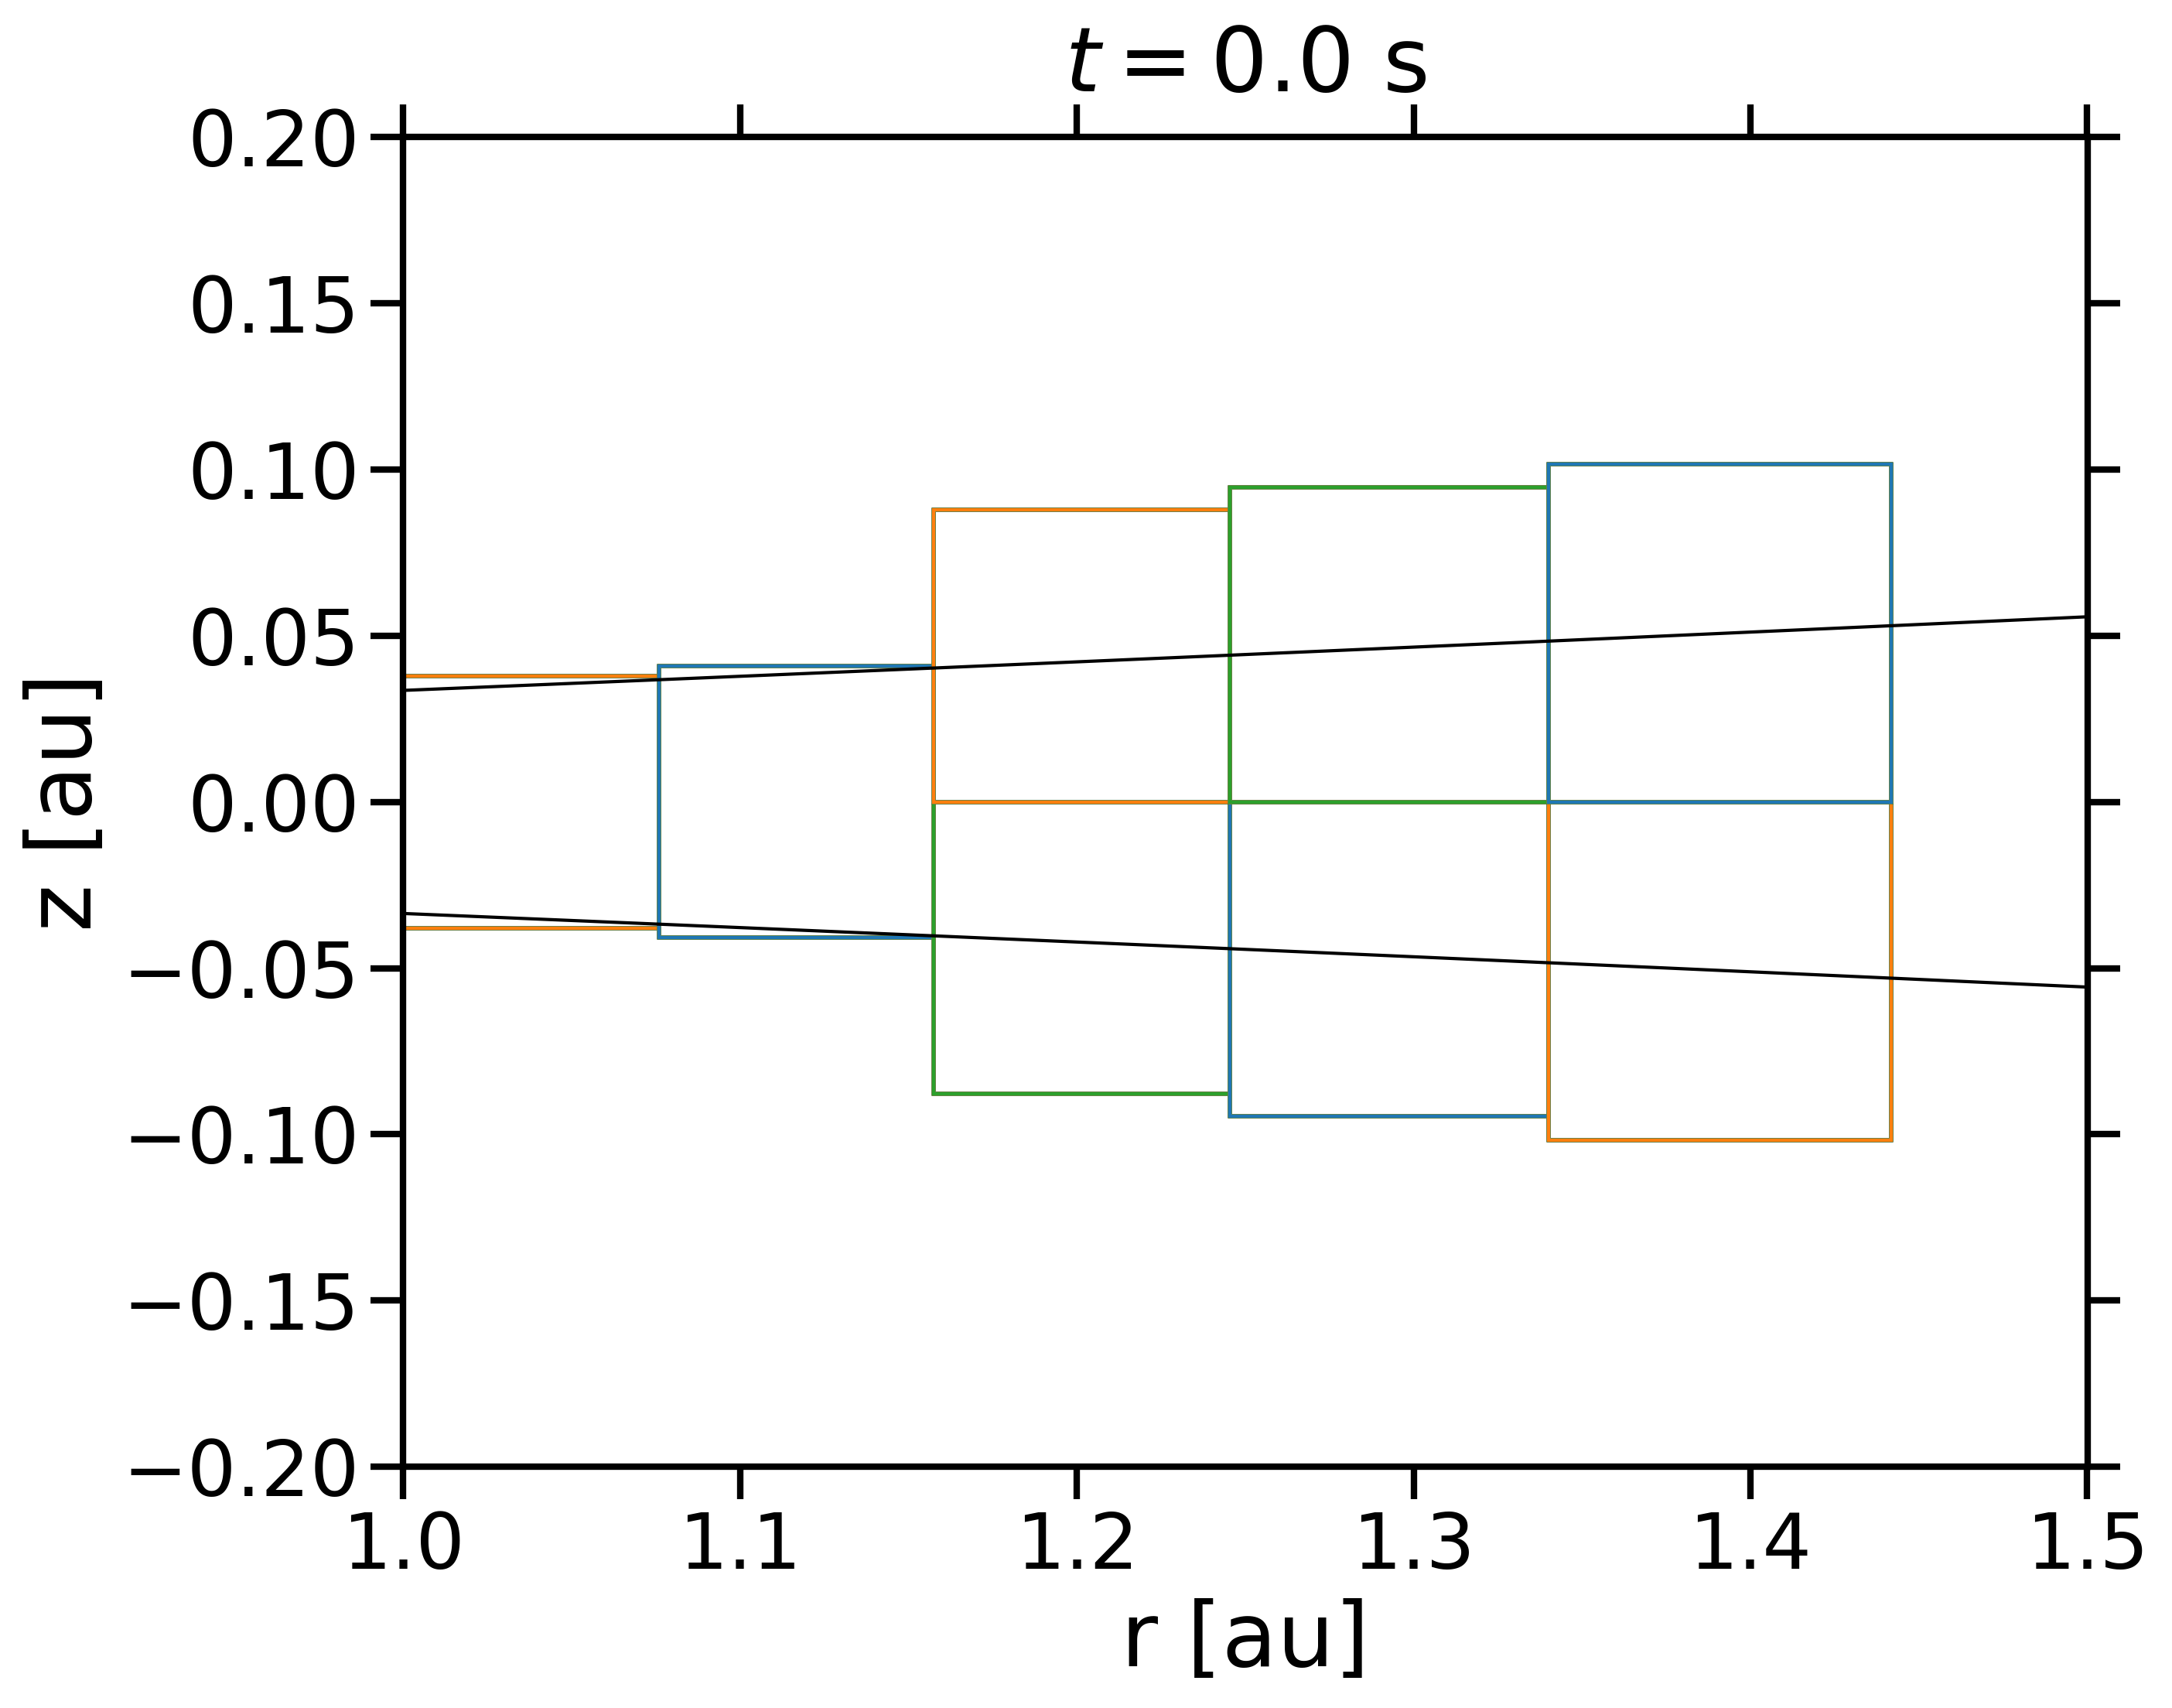

In [5]:
radMin = 1.
radMax = 1.5

figure = plt.figure()
axes = figure.add_subplot(111)

snap = dispatch.snapshot(iout = 0, data = "../data")
for i, patch in enumerate(snap.patches):
    drawPatch(patch, i)

drawScaleHeight(radMin, radMax)

axes.set_xlim(radMin, radMax)
axes.set_xlabel("r [au]")
axes.set_ylim(-0.2, 0.2)
axes.set_ylabel("z [au]")
axes.set_title(r"$t=$%.1f s" % snap.dict["time"], y = 1.02)
plt.tick_params(top = True, right = True, which = "both")
figure.savefig("geometry_radial-vertical_plane")